# How `bila/control/insert_book.py` puts a book on the shelf

This notebook runs one episode of the scripted controller and stops at each layer:

1. **Geometry**: where the book has to go, worked out from the books beside the slot. No IK here.
2. **IK**: `ArmIK`, damped least-squares differential IK, which turns a hand pose into 7 joint angles.
3. **Choosing the arm configuration**: many joint solutions reach the same pose, so `choose_arm` samples them.
4. **Execution**: `Episode.reshelve()` picks the high-level steps (widen, insert, ...). `Runner` follows
   min-jerk Cartesian paths, re-solving IK on every physics step and feeding the position actuators.
5. **What happened**: commanded vs actual hand pose, wrist force, video, score.

Shelf frame: x along the row, y out of the shelf, z up.

"tight, seed 0: the settled scene"

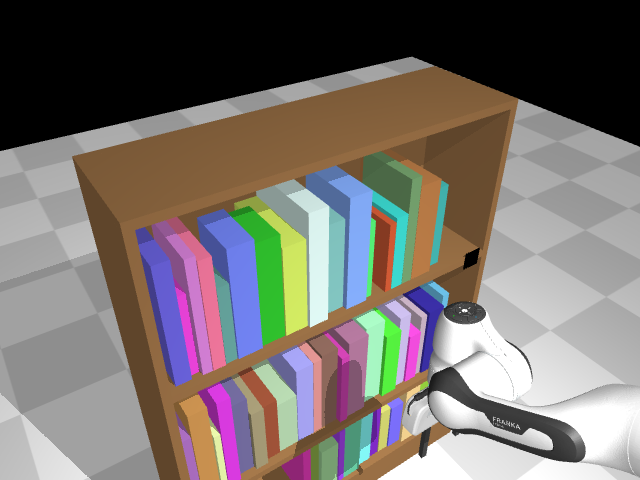

In [1]:
import sys, contextlib, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))     # repo root: the bila package is there
import numpy as np, mujoco, mediapy
import matplotlib.pyplot as plt
from bila.control import insert_book as ib
from bila.sim.shelf_scene import ShelfConfig

SCENARIO, SEED = "tight", 0
model, data, row = ib.make_episode(ShelfConfig(), SCENARIO, np.random.default_rng(SEED), ib.DEFAULT_PANDA)
renderer = mujoco.Renderer(model, 480, 640)
renderer.update_scene(data, "scene_cam")
mediapy.show_image(renderer.render(), title=f"{SCENARIO}, seed {SEED}: the settled scene")

## 1. Geometry: where the book should go

The controller measures the slot from the neighbouring books' boxes (`Episode.slot`). In camera mode
these come from a `ShelfEstimate` instead of `MjData`. From the slot and the held book's size it
derives:

* `book_pre(x)`: the book's centre at the **pre-insertion pose**. It is lined up with the gap, its back
  1 cm over the board's front edge and 3 mm above the board.
* `seat_target()`: how deep the spine should end up. Either *flush* with the neighbour that sticks out
  more, or *inside* the board's front edge.
* `grasp_pose(sign, centre)`: the **hand** pose that holds the book at that centre (pinched 11.5 cm
  above its bottom, spine 2 mm off the palm). `sign` picks which way the hand faces along the row.

All of this is plain geometry. IK only comes in once a hand pose has to become joint angles.

In [2]:
ep = ib.Episode(model, data, row, log=lambda *a: None)
xl, xr, yl, yr = ep.slot()
print(f"slot: x {1000*xl:.1f} .. {1000*xr:.1f} mm  ->  gap {1000*(xr-xl):.1f} mm for a {1000*ep.t:.1f} mm book")
print(f"neighbours' spines at y = {1000*yl:.1f} / {1000*yr:.1f} mm")
target_y, rule = ep.seat_target()
print(f"seat target: spine at y = {1000*target_y:.1f} mm ({rule})")

pre = ep.book_pre((xl + xr) / 2)
hand_pos, hand_rot = ep.grasp_pose(1, pre)
print("book centre at pre-insertion (shelf frame):", np.round(pre, 4))
print("hand pose for it (world):", np.round(hand_pos, 4))
print(np.round(hand_rot, 3))
print("\nthe gap is short of the book, so reshelve() will widen it before inserting"
      if xr - xl < ep.t + ib.GAP_MARGIN else "\nthe book fits: reshelve() goes straight to insert")

slot: x -109.6 .. -75.0 mm  ->  gap 34.6 mm for a 47.8 mm book
neighbours' spines at y = 112.0 / 102.8 mm
seat target: spine at y = 112.0 mm (flush)
book centre at pre-insertion (shelf frame): [-0.0923  0.2007  0.9136]
hand pose for it (world): [-0.0895  0.4312  0.8828]
[[ 0.     1.     0.006]
 [ 0.     0.006 -1.   ]
 [-1.     0.    -0.   ]]

the gap is short of the book, so reshelve() will widen it before inserting


## 2. IK: hand pose to joint angles (`ArmIK`)

`ArmIK.solve` runs damped least squares on the `panda/hand` body:

$$\Delta q = J^\top (J J^\top + \lambda I)^{-1} e + N\,k\,(q_\text{rest} - q), \qquad N = I - J^+ J$$

* `e` is the 6-D error: position, plus a rotation error built from the cross products of the frame axes.
* The Panda has 7 joints for a 6-D task. The spare degree of freedom is pulled toward a rest posture
  through an exact null-space projector `N`, so the pull never disturbs the hand pose.
* A joint pinned at its limit and pushed further into it is dropped from `J`, and the others make up for it.

`solve_far` runs 400 iterations from a distant seed. Below it starts from a few random seeds and solves
for the grasp pose above. Different seeds land in different arm configurations, and some don't converge
at all.

In [3]:
# Both ways of holding the book (grasp sign +1 / -1), 40 random seeds each, as choose_arm does.
rng = np.random.default_rng(0)
sols = []                                       # (grasp sign, q, margin)
for gs in (1, -1):
    pos, rot = ep.grasp_pose(gs, pre)
    n_ok = 0
    for _ in range(40):
        q, ok = ep.ik.solve_far(rng.uniform(ep.ik.lo, ep.ik.hi), pos, rot)
        if ok and not any(g == gs and np.allclose(q, q2, atol=0.05) for g, q2, _ in sols):
            sols.append((gs, q, ep.ik.margin(q)))
        n_ok += ok
    print(f"grasp sign {gs:+d}: {n_ok}/40 seeds converged")
sols.sort(key=lambda s: -s[2])
print(f"\n{len(sols)} distinct solutions; joint-limit margin (rad) of each:")
for gs, q, m in sols:
    print(f"  grasp {gs:+d}  margin {m:.3f}  q = {np.round(q, 2)}")

grasp sign +1: 4/40 seeds converged


grasp sign -1: 16/40 seeds converged

15 distinct solutions; joint-limit margin (rad) of each:
  grasp -1  margin 0.382  q = [-1.32 -1.2   0.89 -2.69  2.43  2.16 -0.87]
  grasp -1  margin 0.374  q = [-1.36 -1.26  0.92 -2.7   2.44  2.12 -0.82]
  grasp -1  margin 0.358  q = [ 1.   -1.4  -1.09 -2.58 -2.47  2.63  2.15]
  grasp -1  margin 0.221  q = [-1.55 -1.54  1.   -2.73  2.53  1.92 -0.58]
  grasp -1  margin 0.059  q = [ 0.23 -0.68 -0.38 -2.48  2.84  2.88 -2.3 ]
  grasp -1  margin 0.022  q = [-2.4   0.98  2.23 -2.49 -2.8   2.87  2.88]
  grasp +1  margin 0.000  q = [ 0.3  -0.7  -0.45 -2.48  2.9   2.9   0.74]
  grasp +1  margin 0.000  q = [ 1.16 -1.76 -1.13 -2.64 -2.41  2.39 -1.35]
  grasp +1  margin 0.000  q = [ 0.68 -0.91 -0.85 -2.48 -2.9   2.9  -0.09]
  grasp -1  margin 0.000  q = [-2.84  0.7   2.69 -2.48  2.9   2.9  -2.4 ]
  grasp -1  margin 0.000  q = [ 1.16 -1.76 -1.13 -2.64 -2.41  2.39  1.79]
  grasp -1  margin 0.000  q = [-1.68 -1.76  1.04 -2.76  2.62  1.79 -0.4 ]
  grasp -1  margi

margin 0.38 rad,margin 0.00 rad

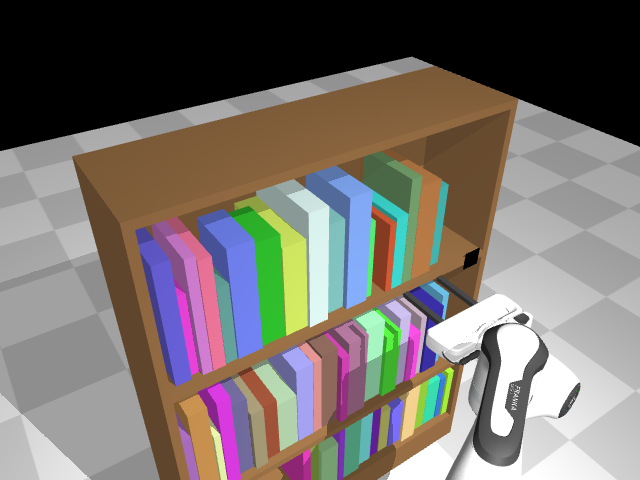
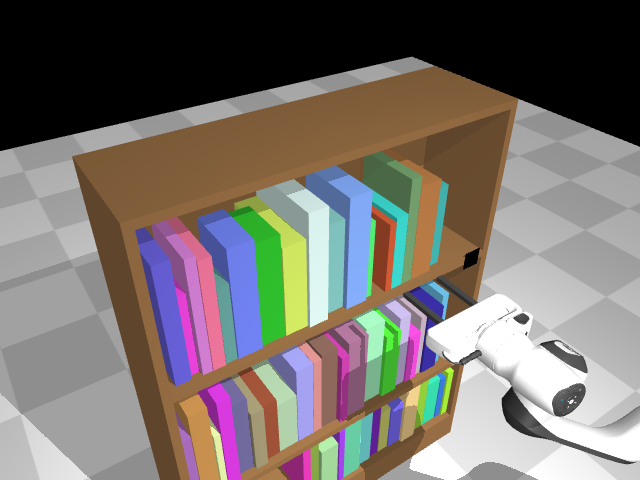

In [4]:
# The best and the worst of them: the same book pose, very different arms.
imgs = []
for gs, q, m in (sols[0], sols[-1]):
    d = mujoco.MjData(model); d.qpos[:] = data.qpos; d.qpos[ep.ik.qadr] = q
    mujoco.mj_forward(model, d)
    renderer.update_scene(d, "scene_cam"); imgs.append(renderer.render())
mediapy.show_images(imgs, titles=[f"margin {sols[0][2]:.2f} rad", f"margin {sols[-1][2]:.2f} rad"])

## 3. Choosing the arm configuration (`choose_arm`)

A configuration that reaches the *start* pose can still run into a joint limit or the shelf halfway along
the path. Before each step `choose_arm`:

1. draws `IK_SEEDS` random seeds and runs `solve_far` from each one to the step's start pose;
2. for each converged solution, sets it as `q_rest` and simulates the whole planned path with
   `ArmIK.follow` (a few warm-started solves per waypoint, collision checks against the books as
   believed);
3. keeps the solution whose **worst joint-limit margin along the path** is largest and that stays clear.

That solution's posture becomes `q_rest` for the run, so the null-space pull keeps the arm in that family.
Below, the insertion's planned path (`insertion_plan`: rest, slide, let go, push home) is scored for each
solution from section 2 (with its own grasp sign).

In [5]:
obs = ep.obstacles()
ep.ik.sync(data)
plans = {gs: ep.insertion_plan(gs, 1, (xl + xr) / 2, pre[1], obs) for gs in (1, -1)}
for gs, q, m in sols:
    ep.ik.q_rest = q
    _, worst, reached = ep.ik.follow(q, plans[gs], allowed=frozenset())
    print(f"grasp {gs:+d}, start margin {m:.3f}: worst margin on the path {worst:.3f} rad, "
          f"{'reaches the end clear' if reached else 'fails (limit or collision)'}")
print(f"\n{len(plans[1])} hand poses in a plan; the runner interpolates between them with min-jerk timing")

grasp -1, start margin 0.382: worst margin on the path 0.051 rad, reaches the end clear
grasp -1, start margin 0.374: worst margin on the path 0.000 rad, reaches the end clear
grasp -1, start margin 0.358: worst margin on the path 0.000 rad, reaches the end clear


grasp -1, start margin 0.221: worst margin on the path 0.000 rad, reaches the end clear
grasp -1, start margin 0.059: worst margin on the path 0.000 rad, reaches the end clear


grasp -1, start margin 0.022: worst margin on the path 0.000 rad, reaches the end clear
grasp +1, start margin 0.000: worst margin on the path 0.000 rad, reaches the end clear
grasp +1, start margin 0.000: worst margin on the path 0.000 rad, reaches the end clear


grasp +1, start margin 0.000: worst margin on the path 0.000 rad, reaches the end clear
grasp -1, start margin 0.000: worst margin on the path 0.000 rad, fails (limit or collision)


grasp -1, start margin 0.000: worst margin on the path 0.000 rad, reaches the end clear
grasp -1, start margin 0.000: worst margin on the path 0.000 rad, reaches the end clear
grasp -1, start margin 0.000: worst margin on the path 0.000 rad, reaches the end clear


grasp -1, start margin 0.000: worst margin on the path 0.000 rad, fails (limit or collision)
grasp -1, start margin 0.000: worst margin on the path 0.000 rad, reaches the end clear

135 hand poses in a plan; the runner interpolates between them with min-jerk timing


## 4. Execution: `reshelve()` and the `Runner`

`Episode.reshelve` is a loop: look at the slot, pick the next step (`next_step`), do it, look again.

* a neighbour leans in → `stand_up`
* the gap is too narrow and the fingers fit → `widen`; they don't fit → `shove`
* otherwise → `insert`

Each step moves the arm through `Runner.move` / `Runner.follow`. On **every physics step** these
interpolate the hand target along a min-jerk path and call `ik.solve(q_cmd, target, rot)`: 2 iterations,
warm-started from the last command. The result becomes the position actuators' setpoint. Contact moves
(sliding the book in, pushes) stop early when the smoothed wrist force along the approach axis jumps
(`stop_force`), so a jammed book isn't forced.

`Runner` already calls `viewer.sync()` at 60 fps. A small stand-in viewer records frames and a trace from
that hook. Nothing in the controller changes.

In [6]:
hand = model.body("panda/hand").id
log, frames, trace = [], [], []

class Recorder:                        # stands in for mujoco.viewer's passive viewer
    user_scn = mujoco.MjvScene(model, 100)
    n = 0
    def lock(self): return contextlib.nullcontext()
    def is_running(self): return True
    def sync(self):
        self.n += 1
        run = ep.run                   # the Runner (created by the first step)
        trace.append((data.time, run.doing, run.pos.copy(), data.xpos[hand].copy(), run.wrist_force()))
        if self.n % 4 == 0:            # 15 fps of video
            renderer.update_scene(data, "scene_cam"); frames.append(renderer.render())

ep = ib.Episode(model, data, row, viewer=Recorder(), log=lambda *a: log.append(" ".join(map(str, a))))
res = ep.reshelve()
print("\n".join(log))
print()
print(ib.report(res))

  -- widen
   0.00 s  put the fingers into the gap
   2.39 s  push the left neighbour to its mark
   4.36 s  push the left neighbour further to its mark
   4.80 s  back to the middle
   5.35 s  take the fingers out
         the gap is now 53.3 mm at the spines and 50.3 mm at its narrowest, for a 47.8 mm book
  -- insert
         wedge the book in +1 mm off the gap's middle: it meets a neighbour 174 mm behind the spines
   7.73 s  move to the start of the next step
   9.83 s  take the book (the hand-over is not modelled)
  10.33 s  rest it on the board
  10.79 s  wedge it in
  16.79 s  open the gripper
  17.19 s  back off
  18.41 s  turn the hand to push
  20.38 s  reach the spine
  20.68 s  push it into place
  22.78 s  back out
  23.97 s  let it settle

  SUCCESS [widen, insert]: tilt 0.0 deg, spine +0.7 mm from the neighbour's, released
  other books: most moved 17.4 mm (all together 83 mm), most tilted 0.0 deg | let go after 17.2 s, in place after 22.8 s


In [7]:
mediapy.show_video(frames, fps=15, title=f"{SCENARIO}, seed {SEED}: {res.get('method')}")

"tight, seed 0: widen, insert This browser does not support the video tag."


## 5. Commanded vs actual hand, and the wrist force

* **Top**: the hand target the runner hands to IK (`run.pos`, solid) against where the hand actually is
  (`xpos`, dashed), per world axis. They separate while the hand pushes on something: the position
  actuators are compliant, and the books push back.
* **Middle**: the tracking error.
* **Bottom**: the wrist force sensor. The contact moves stop on this signal.

Shaded bands are the named moves from the log.

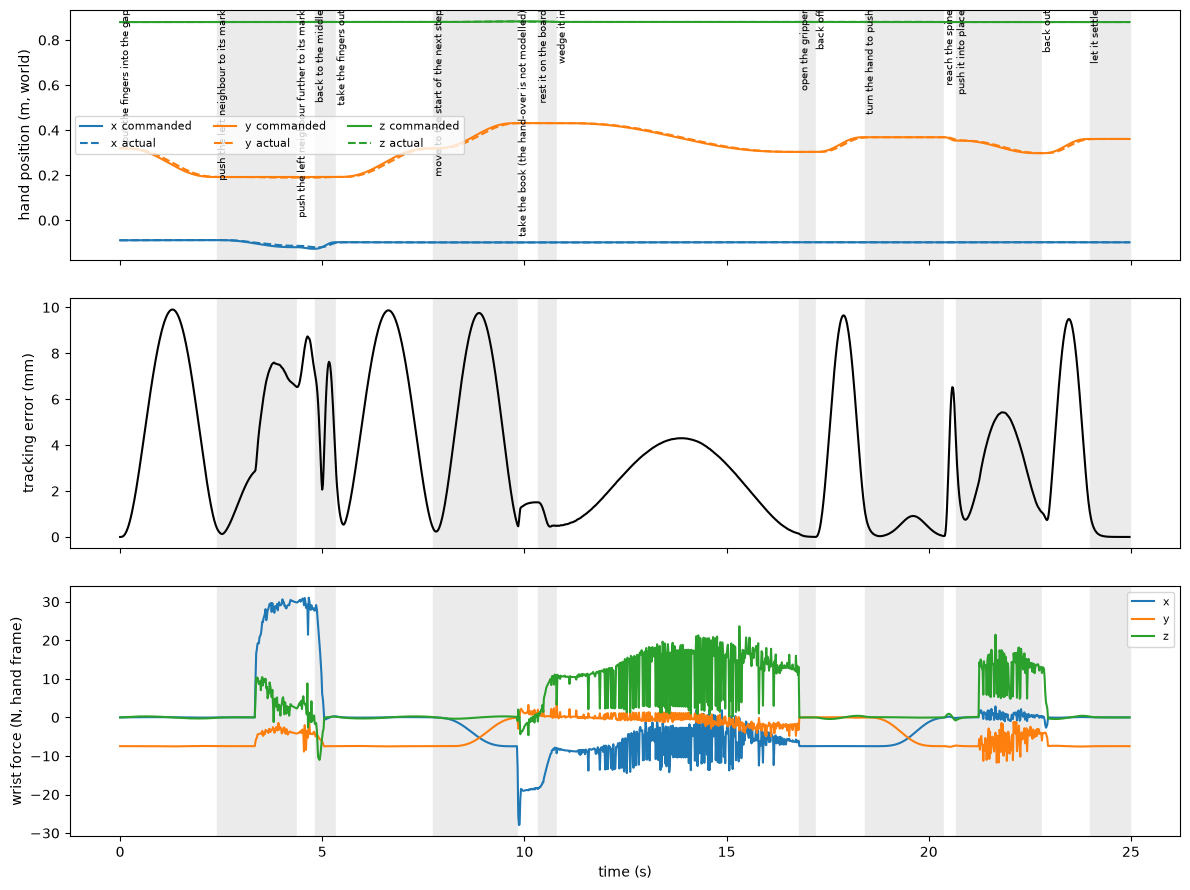

In [8]:
t = np.array([r[0] for r in trace]); t -= t[0]
cmd = np.array([r[2] for r in trace]); act = np.array([r[3] for r in trace]); f = np.array([r[4] for r in trace])
doing = [r[1] for r in trace]

fig, ax = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for i, c in enumerate("xyz"):
    ax[0].plot(t, cmd[:, i], f"C{i}", label=f"{c} commanded")
    ax[0].plot(t, act[:, i], f"C{i}--", label=f"{c} actual")
ax[0].set_ylabel("hand position (m, world)"); ax[0].legend(ncol=3, fontsize=8)
ax[1].plot(t, 1000 * np.linalg.norm(cmd - act, axis=1), "k")
ax[1].set_ylabel("tracking error (mm)")
ax[2].plot(t, f); ax[2].set_ylabel("wrist force (N, hand frame)"); ax[2].legend(list("xyz"), fontsize=8)
ax[2].set_xlabel("time (s)")

starts = [0] + [k for k in range(1, len(doing)) if doing[k] != doing[k - 1]] + [len(doing) - 1]
for j, (a, b) in enumerate(zip(starts, starts[1:])):
    for axi in ax:
        axi.axvspan(t[a], t[b], color="0.92" if j % 2 else "white", zorder=-1)
    ax[0].text(t[a], ax[0].get_ylim()[1], doing[a], rotation=90, va="top", fontsize=7)
plt.tight_layout()

## Try other rows

Set `SCENARIO` to `clear`, `leaning` or `packed` (and change `SEED`) in the first code cell, then rerun.
A leaning row adds a `stand_up` step and a packed one a `shove`. The IK and runner machinery is the same.